# 01 - Exploratory Data Analysis
Goal: understand the data before modelling. Every plot is saved to `figures/` for the report.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/transit_dataset.csv", parse_dates=["transit_timestamp"])
df.shape

(64512, 36)

## 1. Basic checks: size, types, missing values

In [2]:
print(df.shape)
df.head()

(64512, 36)


,transit_timestamp,window_id,ridership,bus_route,borough,gtfs_n_stops,gtfs_max_stops_per_trip,gtfs_n_directions,sched_trips_hr,sched_headway_min,...,hour_cos,is_am_peak,is_pm_peak,is_holiday,is_school_day,lag_1h,lag_24h,lag_168h,roll_24h_mean,roll_168h_mean
0,2025-01-13,0,14,B1,Brooklyn,98,50,2,3,40.0,...,1.0,0,0,0,1,61.0,33.0,17.0,282.791667,417.255952
1,2025-01-13,0,42,B35,Brooklyn,93,47,2,6,20.0,...,1.0,0,0,0,1,102.0,66.0,42.0,260.375000,421.898810
2,2025-01-13,0,30,B38,Brooklyn,82,39,2,3,40.0,...,1.0,0,0,0,1,92.0,74.0,37.0,246.458333,387.273810
3,2025-01-13,0,40,B41,Brooklyn,106,47,2,6,20.0,...,1.0,0,0,0,1,84.0,69.0,47.0,274.875000,441.815476
4,2025-01-13,0,68,B6,Brooklyn,160,82,2,8,15.0,...,1.0,0,0,0,1,98.0,76.0,40.0,358.416667,591.511905


In [3]:
df.isna().sum().sum(), df.duplicated(["bus_route", "transit_timestamp"]).sum()

(np.int64(0), np.int64(0))

The first number is the total count of missing values. The second is the count of duplicate route-hour rows. Both should be 0.

In [4]:
df.describe().T[["mean", "std", "min", "max"]].round(1)

,mean,std,min,max
transit_timestamp,2025-05-28 14:30:00,NaN,2025-01-13 00:00:00,2025-09-28 23:00:00
window_id,3.5,2.291306,0.0,7.0
ridership,462.481771,395.199871,0.0,3336.0
gtfs_n_stops,79.583333,39.281255,24.0,160.0
gtfs_max_stops_per_trip,40.041667,20.107118,13.0,82.0
gtfs_n_directions,2.0,0.0,2.0,2.0
sched_trips_hr,13.514137,8.294396,0.0,38.0
sched_headway_min,18.073474,23.992146,3.157895,120.0
sched_trips_day,324.339286,92.025414,152.0,591.0
temperature_2m,13.732775,11.615362,-16.7,37.0


## 2. Plot 1: distribution of the target (ridership)

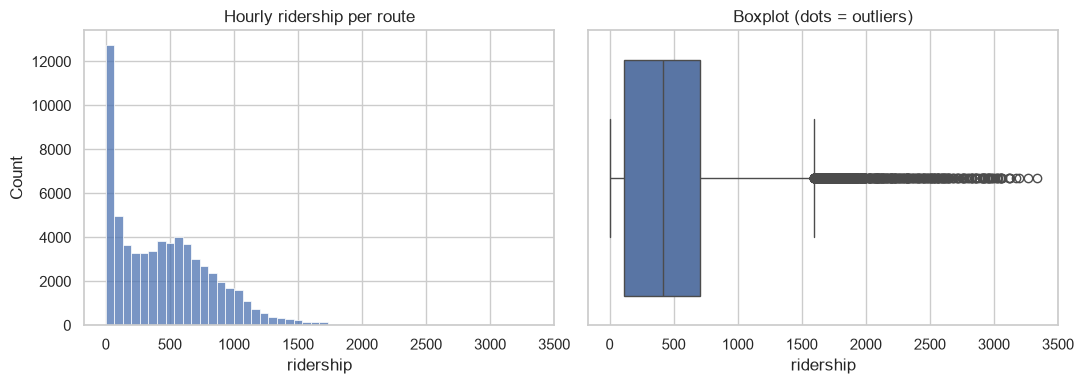

share of hours with 0 riders: 2.7 %


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["ridership"], bins=50, ax=ax[0])
ax[0].set_title("Hourly ridership per route")
sns.boxplot(x=df["ridership"], ax=ax[1])
ax[1].set_title("Boxplot (dots = outliers)")
plt.tight_layout()
plt.savefig("../figures/01_target_distribution.png", dpi=150)
plt.show()
print("share of hours with 0 riders:", round((df["ridership"] == 0).mean() * 100, 1), "%")

Ridership is right-skewed. The tall bar at zero is the overnight hours (about 2.7% of rows are exactly 0), then there is a bulge around 600 for normal daytime hours. The dots on the boxplot are outliers, but they are real rush hours and not errors, so we **keep them**.

## 3. Plot 2: ridership by hour of day (weekday vs weekend)

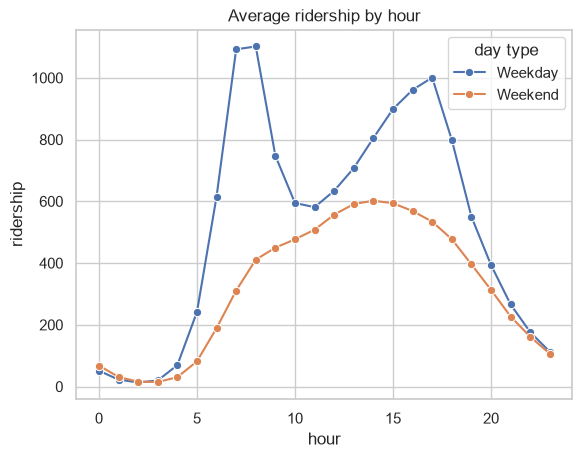

In [6]:
hourly = df.groupby(["hour", "is_weekend"])["ridership"].mean().reset_index()
hourly["day type"] = hourly["is_weekend"].map({0: "Weekday", 1: "Weekend"})
sns.lineplot(data=hourly, x="hour", y="ridership", hue="day type", marker="o")
plt.title("Average ridership by hour")
plt.savefig("../figures/02_hour_profile.png", dpi=150)
plt.show()

Weekdays have two peaks: a sharp one at 7-8 am and a broader one around 4-5 pm (about 1,100 and 1,000 riders per route-hour). Weekends have one smooth midday hump around 2 pm, at a much lower level. So `hour` and `is_weekend` should matter a lot.

## 4. Plot 3: ridership by route

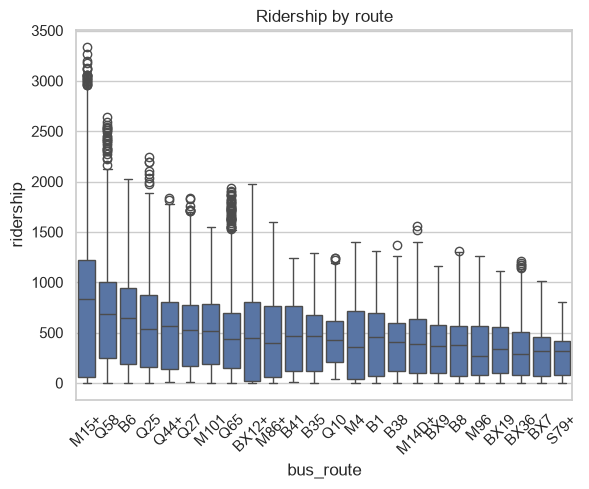

In [7]:
order = df.groupby("bus_route")["ridership"].mean().sort_values(ascending=False).index
sns.boxplot(data=df, x="bus_route", y="ridership", order=order)
plt.xticks(rotation=45)
plt.title("Ridership by route")
plt.savefig("../figures/03_route_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

Routes differ a lot in size, so the model needs to know the route. This is why `bus_route` is a model input.

## 5. Plot 4: weather vs ridership

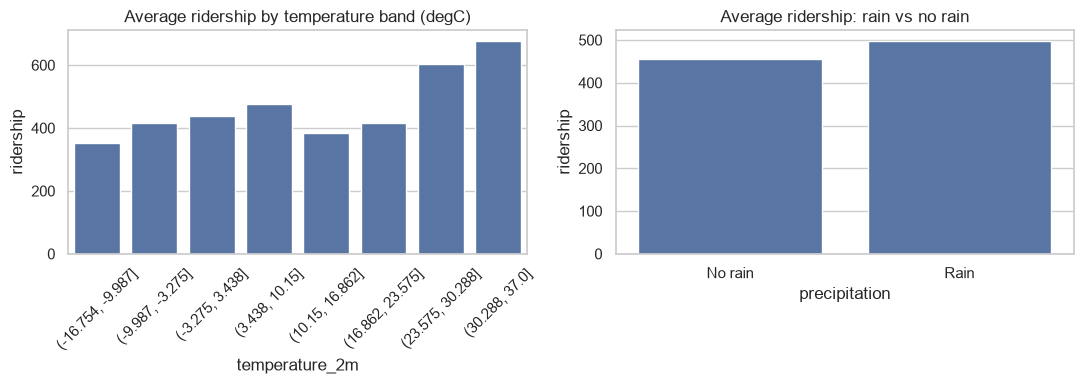

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
temp_bins = pd.cut(df["temperature_2m"], bins=8)
sns.barplot(x=temp_bins, y=df["ridership"], ax=ax[0], errorbar=None)
ax[0].set_title("Average ridership by temperature band (degC)")
ax[0].tick_params(axis="x", rotation=45)
rain = (df["precipitation"] > 0).map({False: "No rain", True: "Rain"})
sns.barplot(x=rain, y=df["ridership"], ax=ax[1], errorbar=None)
ax[1].set_title("Average ridership: rain vs no rain")
plt.tight_layout()
plt.savefig("../figures/04_weather.png", dpi=150)
plt.show()

**Careful:** this raw plot is misleading. Ridership looks higher when it is hot or rainy, but those hours are mostly afternoons, which are busy anyway. To remove the time-of-day effect, we compare each hour with the usual ridership for that same route, hour and day type (weekday/weekend).

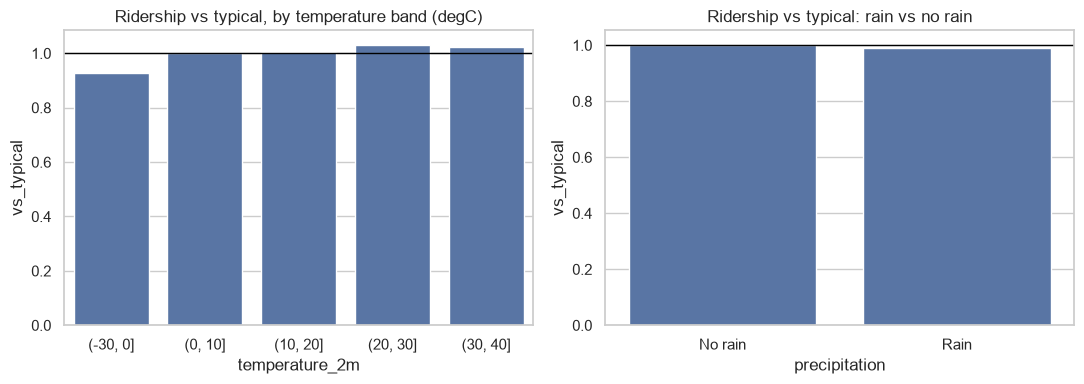

In [9]:
typical = df.groupby(["bus_route", "hour", "is_weekend"])["ridership"].transform("mean")
df["vs_typical"] = df["ridership"] / typical.where(typical > 0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=pd.cut(df["temperature_2m"], [-30, 0, 10, 20, 30, 40]), y=df["vs_typical"], ax=ax[0], errorbar=None)
ax[0].set_title("Ridership vs typical, by temperature band (degC)")
ax[0].axhline(1, color="black", linewidth=1)
sns.barplot(x=rain, y=df["vs_typical"], ax=ax[1], errorbar=None)
ax[1].set_title("Ridership vs typical: rain vs no rain")
ax[1].axhline(1, color="black", linewidth=1)
plt.tight_layout()
plt.savefig("../figures/04b_weather_adjusted.png", dpi=150)
plt.show()

After the adjustment, 1.0 means a normal hour. Rain lowers ridership by only about 1% and freezing weather (below 0 degC) by about 7%. Warm weather (above 20 degC) is about 3% above normal, but that partly reflects the season (summer days) and not the temperature itself. The weather effect is real but **small** compared to hour of day and route. The ablation study later will test this properly with the models.

## 6. Plot 5: correlation heatmap

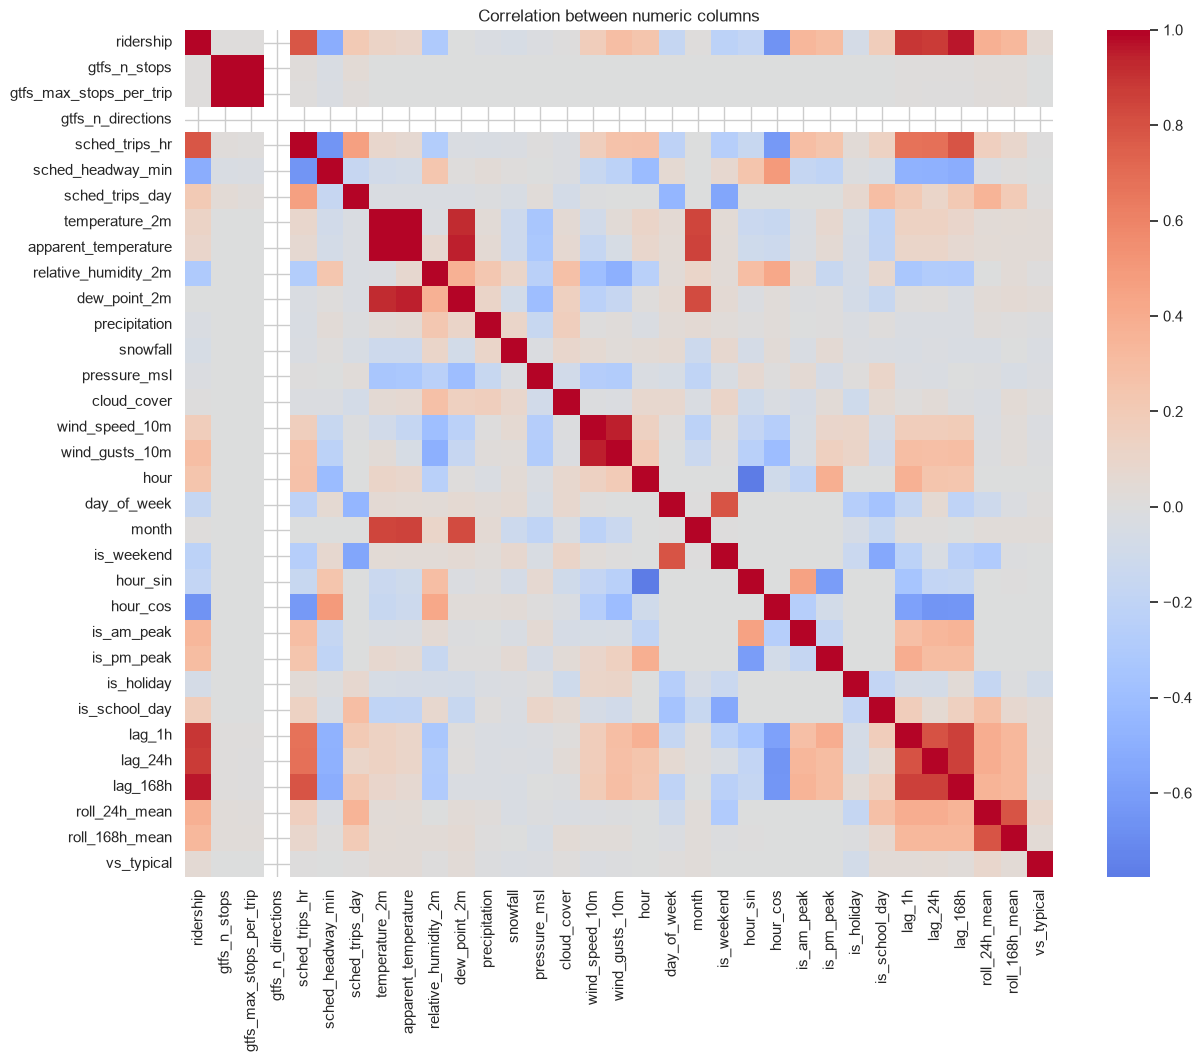

lag_168h                   0.96
lag_1h                     0.89
lag_24h                    0.88
sched_trips_hr             0.78
roll_24h_mean              0.38
is_am_peak                 0.33
roll_168h_mean             0.33
is_pm_peak                 0.31
wind_gusts_10m             0.29
hour                       0.25
sched_trips_day            0.21
wind_speed_10m             0.18
is_school_day              0.18
temperature_2m             0.12
apparent_temperature       0.10
vs_typical                 0.05
gtfs_n_stops               0.01
month                      0.01
gtfs_max_stops_per_trip    0.01
cloud_cover                0.00
dew_point_2m              -0.00
pressure_msl              -0.02
precipitation             -0.03
snowfall                  -0.05
is_holiday                -0.06
day_of_week               -0.17
hour_sin                  -0.18
is_weekend                -0.23
relative_humidity_2m      -0.30
sched_headway_min         -0.51
hour_cos                  -0.65
gtfs_n_d

In [10]:
num = df.drop(columns=["transit_timestamp", "window_id", "bus_route", "borough"])
plt.figure(figsize=(14, 11))
sns.heatmap(num.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation between numeric columns")
plt.savefig("../figures/05_correlation.png", dpi=150, bbox_inches="tight")
plt.show()
num.corr()["ridership"].drop("ridership").sort_values(ascending=False).round(2)

History features (`lag_*`, `roll_*`) and the schedule are strongly correlated with ridership. Some weather columns are correlated with each other (temperature, apparent temperature and dew point), which matters for Linear Regression. `gtfs_n_directions` shows NaN because it is 2 for every route (a constant), so we drop it from the model.

## 7. Plot 6: scheduled trips vs ridership

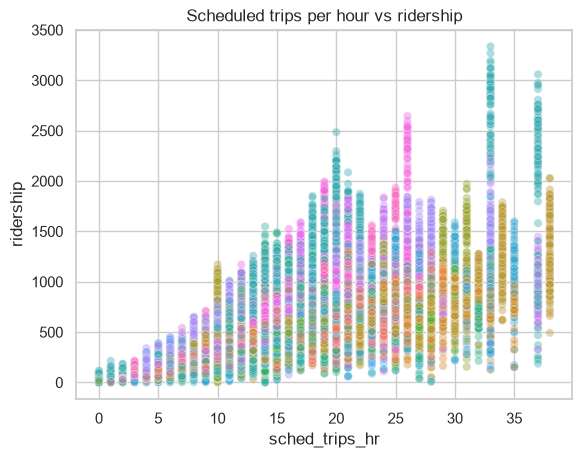

In [11]:
sns.scatterplot(data=df, x="sched_trips_hr", y="ridership", hue="bus_route", alpha=0.4, legend=False)
plt.title("Scheduled trips per hour vs ridership")
plt.savefig("../figures/06_schedule_vs_ridership.png", dpi=150)
plt.show()

More scheduled buses go with more riders. Planners add buses where demand is high, so this is a link and not proof that buses create riders.

## 8. Plot 7: the eight time windows

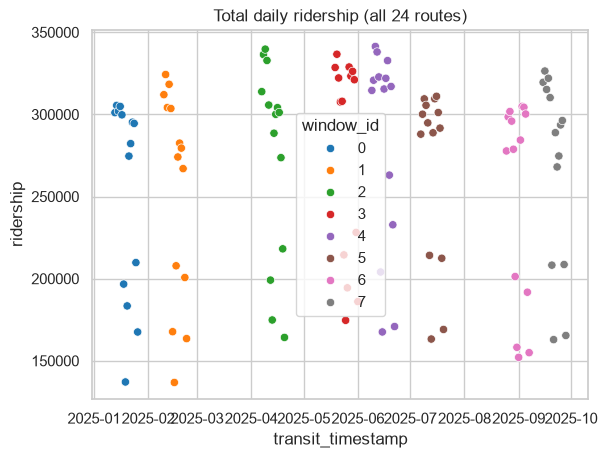

In [12]:
daily = df.groupby([df["transit_timestamp"].dt.date, "window_id"])["ridership"].sum().reset_index()
daily["transit_timestamp"] = pd.to_datetime(daily["transit_timestamp"])
sns.scatterplot(data=daily, x="transit_timestamp", y="ridership", hue="window_id", palette="tab10")
plt.title("Total daily ridership (all 24 routes)")
plt.savefig("../figures/07_daily_total.png", dpi=150, bbox_inches="tight")
plt.show()

The data has eight separate 2-week blocks spread from January to September. Each block shows two clusters: weekdays (about 270-340k riders a day across the 24 routes) and weekends (about 140-230k). All five holidays (Jan 20, Feb 17, May 26, Jun 19, Sep 1) had fewer riders than any normal weekday (152k-263k), and Labor Day (152k) looks like a quiet weekend day. A time-ordered split puts the last 18 days (Sep 4-7 and Sep 15-28) in the test set.

## 9. Do route levels change over the year?

bus_route
Q10      0.61
Q65      0.64
Q58      0.68
Q27      0.87
B35      0.97
B38      0.98
B41      0.98
BX19     0.99
M15+     0.99
B1       1.01
M14D+    1.01
M101     1.01
B8       1.01
M96      1.02
BX36     1.03
BX9      1.03
S79+     1.03
BX7      1.04
M4       1.04
B6       1.05
M86+     1.11
BX12+    1.14
Q44+     1.22
Q25      1.32


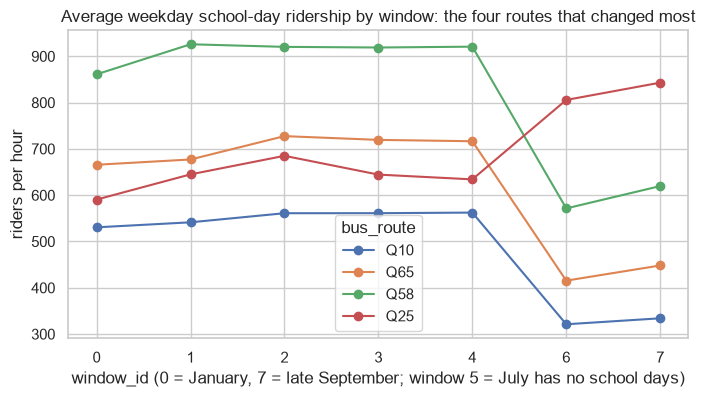

In [13]:
school_weekdays = df[(df["is_weekend"] == 0) & (df["is_holiday"] == 0) & (df["is_school_day"] == 1)]
levels = school_weekdays.pivot_table(index="bus_route", columns="window_id", values="ridership", aggfunc="mean")
levels["Sep vs Jan-Jun"] = levels[7] / levels[[0, 1, 2, 3, 4]].mean(axis=1)
changed = levels.sort_values("Sep vs Jan-Jun").iloc[[0, 1, 2, -1]]
print(levels["Sep vs Jan-Jun"].round(2).sort_values().to_string())
changed.drop(columns="Sep vs Jan-Jun").T.plot(marker="o", figsize=(8, 4))
plt.title("Average weekday school-day ridership by window: the four routes that changed most")
plt.xlabel("window_id (0 = January, 7 = late September; window 5 = July has no school days)")
plt.ylabel("riders per hour")
plt.savefig("../figures/13_route_level_change.png", dpi=150, bbox_inches="tight")
plt.show()

16 of the 24 routes have a late-September weekday level within 5% of January-June. Some moved moderately (Q27 -13%, M86+ +11%, BX12+ +14%, Q44+ +22%). Four Queens routes moved a lot: **Q10, Q65 and Q58 are 32-39% lower** and **Q25 is 32% higher**. Something changed on these routes between June and late August (a service change on the Queens network is likely, but we have not verified the cause). A model trained on earlier months cannot know about such a change.

## Findings so far

- 64,512 rows, 24 routes, 8 two-week windows, no missing values, no duplicate route-hours.
- Target is right-skewed; large values are real rush hours, so they stay.
- Hour of day and weekday/weekend are the strongest patterns. Route size matters too.
- Weather effects are small. The schedule and history features are strongly related to ridership.
- Four Queens routes (Q58, Q10, Q65, Q25) changed ridership level by about 32-39% during the year; 16 of 24 routes stayed within 5%.
- Weather columns are strongly correlated with each other (temperature, apparent temperature, dew point: 0.92-0.99). `gtfs_n_directions` is constant.
- Five US federal holidays are in the data (four in training, one in validation). None is in the test set, so `is_holiday` cannot be checked on the test set.